# H4 — Data Storytelling y Gestalt con K-Means
## GeoRisk AI: cuatro perfiles de condiciones geoclimáticas en Bolivia

**Objetivo.** Aplicar K-Means con cuatro clusters al conjunto de datos de GeoRisk AI para identificar perfiles de observaciones con condiciones climáticas y topográficas similares. La segmentación complementa al modelo supervisado de predicción: no determina por sí sola una alerta, sino que ayuda a comprender patrones presentes en los datos.

> Nota: el conjunto utilizado es sintético y sus resultados tienen fines académicos; no deben emplearse para decisiones reales de emergencia.

## 1. Descripción del análisis

Las variables elegidas para formar los clusters son seis mediciones numéricas disponibles antes de conocer si ocurrió un deslizamiento:

- precipitación acumulada en 24 horas, 3 días y 7 días;
- pendiente del terreno;
- elevación;
- humedad del suelo.

### Origen de las 10.000 observaciones

El archivo se genera con `Dataset_10000_Bolivia_Sintetico.py` y una semilla aleatoria fija (`42`), por lo que el resultado es reproducible. Simula condiciones geoclimáticas de Bolivia y no corresponde a mediciones reales de sensores.

| Variable usada por K-Means | Origen sintético | Qué representa |
|---|---|---|
| Precipitación 24 h (mm) | Distribución exponencial, escala 15 mm | Lluvia inmediata que puede saturar rápidamente el suelo |
| Precipitación 3 días (mm) | Distribución exponencial, escala 45 mm | Episodios recientes de lluvia acumulada |
| Precipitación 7 días (mm) | Escala 120 mm y eventos extremos de 500 u 800 mm | Saturación prolongada del terreno |
| Pendiente (grados) | Distribución normal, media 30°, limitada entre 0° y 90° | Inclinación del terreno |
| Elevación (m) | Distribución uniforme entre 500 y 5.000 m | Diferencia valles y zonas de gran elevación |
| Humedad (%) | Distribución normal, media 60%, limitada entre 0% y 100% | Agua retenida por el suelo |

El dataset también contiene departamento, tipo de suelo y geología como contexto. `indice_riesgo_deslizamiento` y `deslizamiento_ocurrido` son resultados simulados: no participan en la formación de los clusters y se utilizan únicamente para interpretarlos.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)

In [ ]:
# Localizar el dataset independientemente de si el notebook se abre desde la raiz o /notebooks.
from pathlib import Path
import subprocess
import sys

carpetas = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'caso8']
raiz = next((p for p in carpetas if (p / 'Dataset_10000_Bolivia_Sintetico.py').is_file()), None)
if raiz is None:
    raise FileNotFoundError('Abra el notebook dentro del repositorio teletubis, que contiene Dataset_10000_Bolivia_Sintetico.py')

DATASET = raiz / 'Dataset_10000_Bolivia_Sintetico.csv'
if not DATASET.exists():
    # Se generan los datos sintéticos reproducibles antes de comenzar el análisis.
    subprocess.run([sys.executable, str(raiz / 'Dataset_10000_Bolivia_Sintetico.py')], cwd=str(raiz), check=True)

df = pd.read_csv(DATASET)
print(f'Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas')
print(f'Valores nulos: {int(df.isna().sum().sum())}')
df.head()


## 2. Preparación de los datos

Se seleccionan las seis variables, se convierten a valores numéricos y se eliminan registros inválidos o duplicados. Para reducir el efecto de observaciones extremas, cada variable se limita a sus percentiles 1 y 99. Finalmente se aplica `StandardScaler`, paso indispensable porque K-Means utiliza distancias y las variables se encuentran en escalas distintas (metros, milímetros, grados y porcentajes).

In [3]:
variables = [
    'precipitacion_24h_mm', 'precipitacion_3d_mm',
    'precipitacion_7d_mm', 'pendiente_grados',
    'elevacion_m', 'humedad_pct'
]

X = df[variables].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
X_limpio = X.clip(X.quantile(0.01), X.quantile(0.99), axis=1)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_limpio)

print(f'Registros originales: {len(df):,}')
print(f'Registros utilizados: {len(X_limpio):,}')
pd.DataFrame(X_escalado, columns=variables).describe().round(2)

Registros originales: 10,000
Registros utilizados: 10,000


,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,-0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.03,-1.03,-0.84,-2.06,-1.70,-2.40
25%,-0.73,-0.74,-0.66,-0.69,-0.86,-0.69
50%,-0.31,-0.32,-0.38,-0.01,-0.01,-0.01
75%,0.41,0.42,0.18,0.68,0.88,0.70
max,3.80,3.77,3.65,2.40,1.68,2.08


## 3. Selección del número de clusters

Se prueban valores de `k` entre 2 y 6 para observar el **coeficiente Silhouette** y la inercia (WCSS). Para la entrega H4 se fija **k=4**, porque el objetivo de comunicación requiere cuatro perfiles comparables. Las métricas se conservan como diagnóstico de calidad y permiten explicar el compromiso entre separación y detalle narrativo.

In [4]:
resultados_k = []
modelos = {}

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    resultados_k.append({
        'k': k,
        'silhouette': silhouette_score(X_escalado, etiquetas),
        'WCSS': modelo.inertia_
    })
    modelos[k] = modelo

evaluacion = pd.DataFrame(resultados_k)
k_optimo = 4
display(evaluacion.round(4))
print(f'K seleccionado para H4: {k_optimo} clusters. Silhouette y WCSS se usan como diagnóstico.')

,k,silhouette,WCSS
0,2,0.2300,52306.7534
1,3,0.1546,45790.8546
2,4,0.1625,40768.1168
3,5,0.1721,36183.4411
4,6,0.1585,33399.5808


K seleccionado para H4: 4 clusters. Silhouette y WCSS se usan como diagnóstico.


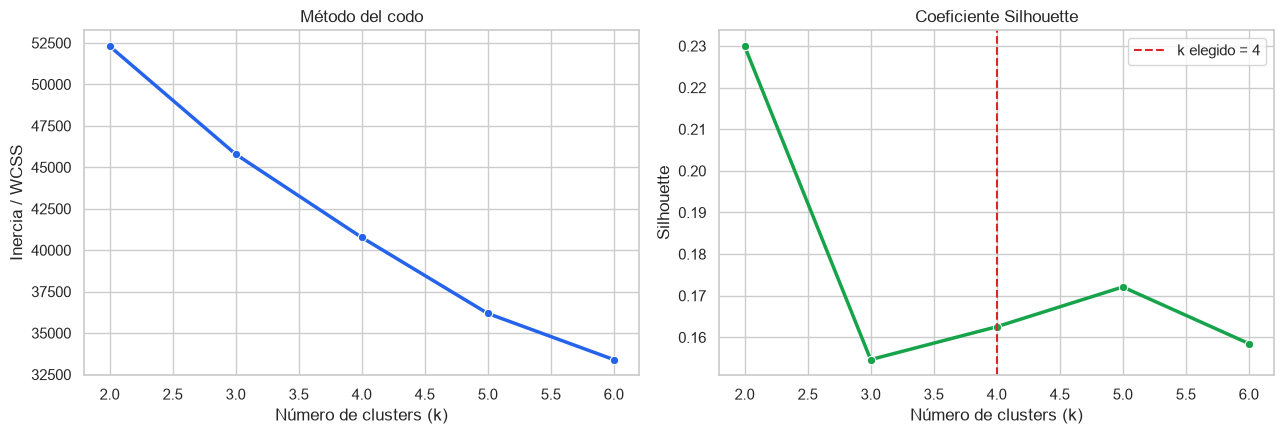

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=evaluacion, x='k', y='WCSS', marker='o', linewidth=2.5, ax=axes[0], color='#2563eb')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia / WCSS')

sns.lineplot(data=evaluacion, x='k', y='silhouette', marker='o', linewidth=2.5, ax=axes[1], color='#16a34a')
axes[1].axvline(k_optimo, color='#dc2626', linestyle='--', label=f'k elegido = {k_optimo}')
axes[1].set_title('Coeficiente Silhouette')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Entrenamiento final y visualización

El modelo final se entrena con el valor de `k` seleccionado. Para visualizar las seis dimensiones en un plano se utiliza PCA. PCA solo se usa para la representación gráfica: los clusters se forman con todas las variables estandarizadas.

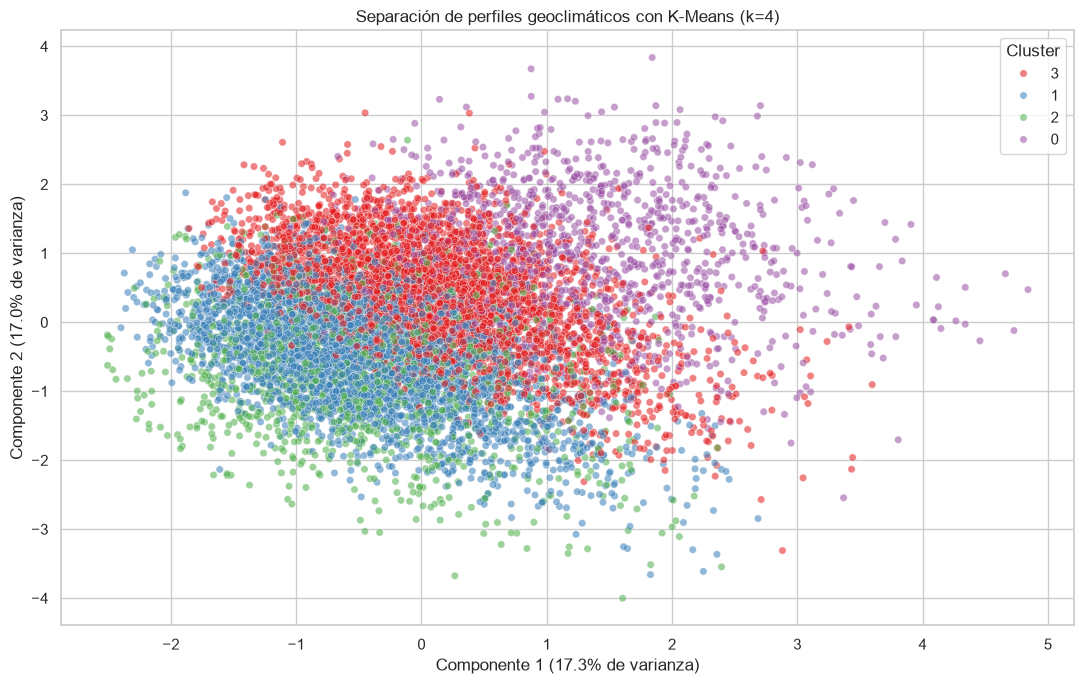

Varianza explicada por los dos componentes: 34.2%


In [6]:
modelo_final = modelos[k_optimo]
clusters = modelo_final.labels_

pca = PCA(n_components=2)
componentes = pca.fit_transform(X_escalado)
grafico = pd.DataFrame({
    'Componente principal 1': componentes[:, 0],
    'Componente principal 2': componentes[:, 1],
    'Cluster': clusters.astype(str)
})

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=grafico, x='Componente principal 1', y='Componente principal 2',
    hue='Cluster', palette='Set1', alpha=0.55, s=28
)
plt.title(f'Separación de perfiles geoclimáticos con K-Means (k={k_optimo})')
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0] * 100:.1f}% de varianza)')
plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1] * 100:.1f}% de varianza)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()
print(f'Varianza explicada por los dos componentes: {pca.explained_variance_ratio_.sum() * 100:.1f}%')

## 5. Caracterización e interpretación de los clusters

Para explicar cada grupo se calculan sus promedios en las unidades originales. Después se incorporan, solo con fines descriptivos, el índice de riesgo y la ocurrencia de deslizamientos. Esto permite relacionar la segmentación no supervisada con el contexto del proyecto sin introducir esas respuestas durante el entrenamiento.

In [7]:
analisis = df.loc[X_limpio.index, variables + [
    'indice_riesgo_deslizamiento', 'deslizamiento_ocurrido'
]].copy()
analisis['cluster'] = clusters

perfiles = analisis.groupby('cluster').agg(
    registros=('cluster', 'size'),
    lluvia_24h_mm=('precipitacion_24h_mm', 'mean'),
    lluvia_3d_mm=('precipitacion_3d_mm', 'mean'),
    lluvia_7d_mm=('precipitacion_7d_mm', 'mean'),
    pendiente_grados=('pendiente_grados', 'mean'),
    elevacion_m=('elevacion_m', 'mean'),
    humedad_pct=('humedad_pct', 'mean'),
    indice_riesgo=('indice_riesgo_deslizamiento', 'mean'),
    tasa_deslizamiento=('deslizamiento_ocurrido', 'mean')
).round(2)
perfiles['tasa_deslizamiento_pct'] = (perfiles['tasa_deslizamiento'] * 100).round(1)
perfiles.drop(columns='tasa_deslizamiento', inplace=True)
perfiles

,registros,lluvia_24h_mm,lluvia_3d_mm,lluvia_7d_mm,pendiente_grados,elevacion_m,humedad_pct,indice_riesgo,tasa_deslizamiento_pct
cluster,,,,,,,,,
0,1295,15.36,37.81,654.99,30.90,2801.04,59.60,56.75,58.0
1,3706,14.60,29.71,104.36,29.78,1618.71,59.46,41.71,41.0
2,1381,14.59,130.79,128.06,30.87,2714.44,59.52,42.59,43.0
3,3618,15.41,30.35,106.55,30.57,3935.57,59.88,42.11,42.0


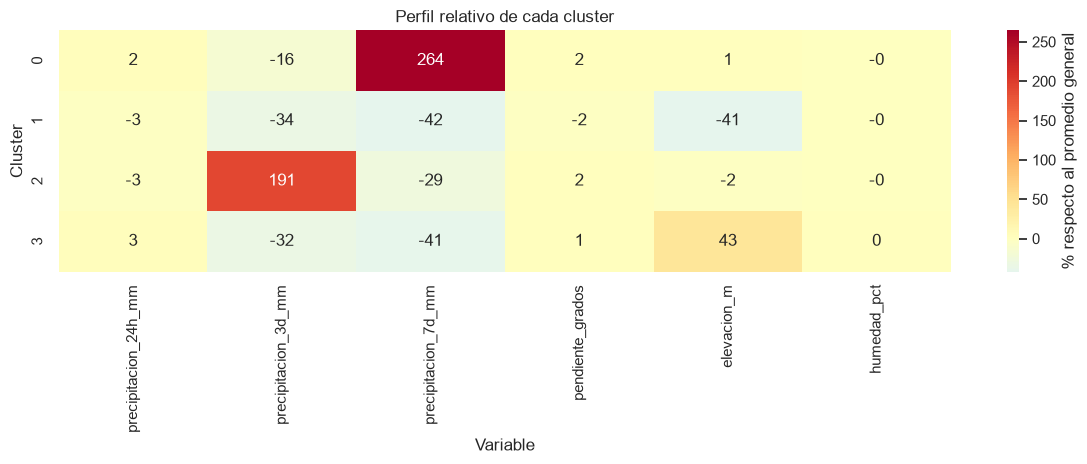

In [8]:
medias_globales = analisis[variables].mean()
perfil_relativo = analisis.groupby('cluster')[variables].mean().div(medias_globales).sub(1).mul(100)

plt.figure(figsize=(12, max(3.5, k_optimo * 1.2)))
sns.heatmap(perfil_relativo, annot=True, fmt='.0f', cmap='RdYlBu_r', center=0, cbar_kws={'label': '% respecto al promedio general'})
plt.title('Perfil relativo de cada cluster')
plt.xlabel('Variable')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

In [9]:
disponibles = set(perfiles.index)
nombres, diferencias = {}, {}
cluster_semanal = perfiles.loc[list(disponibles), 'lluvia_7d_mm'].idxmax()
nombres[cluster_semanal] = 'Saturación por lluvia acumulada'
diferencias[cluster_semanal] = 'Mayor precipitación semanal; representa saturación prolongada.'
disponibles.remove(cluster_semanal)
cluster_reciente = perfiles.loc[list(disponibles), 'lluvia_3d_mm'].idxmax()
nombres[cluster_reciente] = 'Lluvia reciente de alta intensidad'
diferencias[cluster_reciente] = 'Mayor precipitación en tres días entre los perfiles restantes.'
disponibles.remove(cluster_reciente)
cluster_valles = perfiles.loc[list(disponibles), 'elevacion_m'].idxmin()
nombres[cluster_valles] = 'Valles de menor elevación'
diferencias[cluster_valles] = 'Menor elevación media y lluvia acumulada moderada.'
disponibles.remove(cluster_valles)
cluster_altiplano = disponibles.pop()
nombres[cluster_altiplano] = 'Altiplano de gran elevación'
diferencias[cluster_altiplano] = 'Mayor elevación media sin precipitación semanal extrema.'

for cluster, fila in perfiles.iterrows():
    print(f"Cluster {cluster} — {nombres[cluster]}")
    print(f"  Diferenciador: {diferencias[cluster]}")
    print(f"  {int(fila['registros']):,} observaciones; lluvia 7d={fila['lluvia_7d_mm']:.1f} mm; "
          f"pendiente={fila['pendiente_grados']:.1f}°; humedad={fila['humedad_pct']:.1f}%; "
          f"ocurrencia observada={fila['tasa_deslizamiento_pct']:.1f}%.")

cluster_mayor = perfiles['indice_riesgo'].idxmax()
cluster_menor = perfiles['indice_riesgo'].idxmin()
diferencia = perfiles.loc[cluster_mayor, 'tasa_deslizamiento_pct'] - perfiles.loc[cluster_menor, 'tasa_deslizamiento_pct']
print(f'\nHallazgo principal: el cluster {cluster_mayor} presenta la mayor exposición media y una tasa de deslizamiento '      f'de {perfiles.loc[cluster_mayor, "tasa_deslizamiento_pct"]:.1f}%, frente a '      f'{perfiles.loc[cluster_menor, "tasa_deslizamiento_pct"]:.1f}% en el cluster {cluster_menor} '      f'(diferencia de {diferencia:.1f} puntos porcentuales).')

Cluster 0 — Saturación por lluvia acumulada
  Diferenciador: Mayor precipitación semanal; representa saturación prolongada.
  1,295 observaciones; lluvia 7d=655.0 mm; pendiente=30.9°; humedad=59.6%; ocurrencia observada=58.0%.
Cluster 1 — Valles de menor elevación
  Diferenciador: Menor elevación media y lluvia acumulada moderada.
  3,706 observaciones; lluvia 7d=104.4 mm; pendiente=29.8°; humedad=59.5%; ocurrencia observada=41.0%.
Cluster 2 — Lluvia reciente de alta intensidad
  Diferenciador: Mayor precipitación en tres días entre los perfiles restantes.
  1,381 observaciones; lluvia 7d=128.1 mm; pendiente=30.9°; humedad=59.5%; ocurrencia observada=43.0%.
Cluster 3 — Altiplano de gran elevación
  Diferenciador: Mayor elevación media sin precipitación semanal extrema.
  3,618 observaciones; lluvia 7d=106.5 mm; pendiente=30.6°; humedad=59.9%; ocurrencia observada=42.0%.

Hallazgo principal: el cluster 0 presenta la mayor exposición media y una tasa de deslizamiento de 58.0%, frente a 4

## 6. Data Storytelling y principios Gestalt

La historia visual sigue cuatro decisiones: el título comunica el hallazgo, cada cluster ocupa una región común, los colores semejantes mantienen la relación entre datos del mismo grupo y el contraste destaca el perfil de mayor exposición. La proximidad entre métricas y descripción facilita leer cada perfil como una unidad.

## 7. Conclusión

K-Means permite resumir miles de observaciones en cuatro perfiles geoclimáticos comprensibles. Silhouette y el método del codo documentan la calidad relativa de las alternativas, mientras que PCA y el mapa de calor comunican la separación y las características de los cuatro grupos.

El hallazgo relevante es que los grupos formados sin conocer la variable objetivo presentan diferencias observables en el índice y en la frecuencia histórica de deslizamientos. Por ello, la clusterización aporta una capa descriptiva útil para priorizar el análisis de zonas con perfiles semejantes. Sin embargo, los clusters representan asociaciones y no causalidad ni niveles oficiales de alerta. Para una aplicación real se requiere validar el procedimiento con datos de campo, información temporal y evaluación por especialistas.